In [1]:
#cell 1
import torch
import numpy as np
import platform

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("GPU not detected. Check Kaggle Accelerator settings.")

print("NumPy:", np.__version__)

Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
NumPy: 2.1.3


In [2]:
#cell 2
import os
import subprocess

REPO_URL = "https://github.com/arcprize/ARC-AGI-2.git"

PROJECT_DIR = "/kaggle/working/GridMind"
DATA_DIR = os.path.join(PROJECT_DIR, "data")

os.makedirs(PROJECT_DIR, exist_ok=True)

if not os.path.exists(os.path.join(PROJECT_DIR, ".git")):

    subprocess.run(
        [
            "git", "clone",
            "--depth", "1",
            REPO_URL,
            PROJECT_DIR
        ],
        check=True
    )

print("Dataset repository downloaded!")
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

Cloning into '/kaggle/working/GridMind'...


Dataset repository downloaded!
Project directory: /kaggle/working/GridMind
Data directory: /kaggle/working/GridMind/data


In [3]:
#cell 3
import os

TRAIN_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "training"
)

EVAL_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "evaluation"
)

print("Training directory exists:", os.path.exists(TRAIN_DIR))
print("Evaluation directory exists:", os.path.exists(EVAL_DIR))

train_files = [
    f for f in os.listdir(TRAIN_DIR)
    if f.endswith(".json")
]

eval_files = [
    f for f in os.listdir(EVAL_DIR)
    if f.endswith(".json")
]

print("Training tasks:", len(train_files))
print("Evaluation tasks:", len(eval_files))

Training directory exists: True
Evaluation directory exists: True
Training tasks: 1000
Evaluation tasks: 120


In [4]:
#cell 4
folders = [
    "src",
    "checkpoints",
    "experiments",
    "outputs",
    "outputs/visualizations",
    "outputs/predictions"
]

for folder in folders:

    path = os.path.join(PROJECT_DIR, folder)

    os.makedirs(path, exist_ok=True)

print("GridMind project folders created!")

for folder in folders:
    print("✓", folder)

GridMind project folders created!
✓ src
✓ checkpoints
✓ experiments
✓ outputs
✓ outputs/visualizations
✓ outputs/predictions


In [5]:
#cell 5
import json

first_task_file = sorted(train_files)[0]

first_task_path = os.path.join(
    TRAIN_DIR,
    first_task_file
)

with open(first_task_path, "r") as f:
    task = json.load(f)

print("Task ID:", first_task_file.replace(".json", ""))

print("Number of training examples:", len(task["train"]))
print("Number of test examples:", len(task["test"]))

print("\nFirst training input:")
print(np.array(task["train"][0]["input"]))

print("\nFirst training output:")
print(np.array(task["train"][0]["output"]))

print("\nTest input:")
print(np.array(task["test"][0]["input"]))

Task ID: 00576224
Number of training examples: 2
Number of test examples: 1

First training input:
[[7 9]
 [4 3]]

First training output:
[[7 9 7 9 7 9]
 [4 3 4 3 4 3]
 [9 7 9 7 9 7]
 [3 4 3 4 3 4]
 [7 9 7 9 7 9]
 [4 3 4 3 4 3]]

Test input:
[[3 2]
 [7 8]]


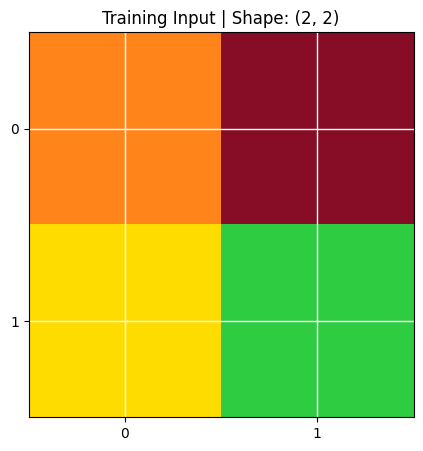

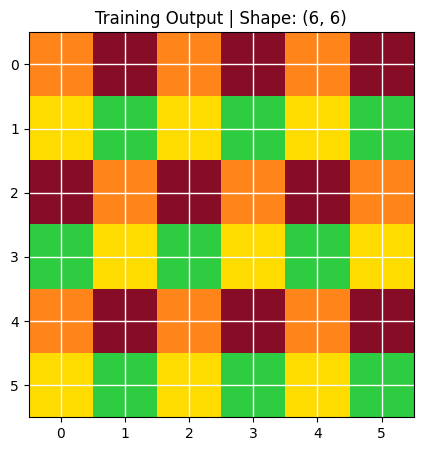

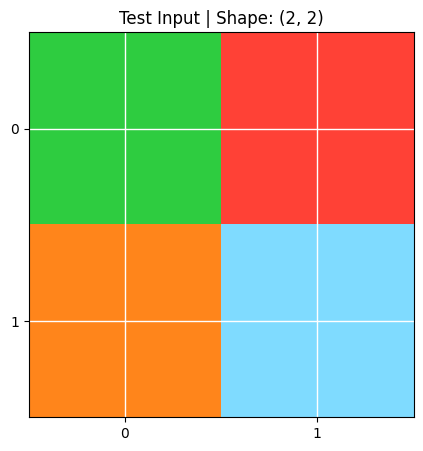

In [6]:
#cell 7
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ARC_COLORS = [
    "#000000",  # 0 - Black
    "#0074D9",  # 1 - Blue
    "#FF4136",  # 2 - Red
    "#2ECC40",  # 3 - Green
    "#FFDC00",  # 4 - Yellow
    "#AAAAAA",  # 5 - Grey
    "#F012BE",  # 6 - Magenta
    "#FF851B",  # 7 - Orange
    "#7FDBFF",  # 8 - Cyan
    "#870C25"   # 9 - Maroon
]

cmap = ListedColormap(ARC_COLORS)


def show_grid(grid, title="ARC Grid"):

    grid = np.array(grid)

    plt.figure(figsize=(5, 5))

    plt.imshow(
        grid,
        cmap=cmap,
        vmin=0,
        vmax=9
    )

    plt.title(
        f"{title} | Shape: {grid.shape}"
    )

    plt.xticks(range(grid.shape[1]))
    plt.yticks(range(grid.shape[0]))

    plt.grid(
        color="white",
        linewidth=1
    )

    plt.show()


show_grid(
    task["train"][0]["input"],
    "Training Input"
)

show_grid(
    task["train"][0]["output"],
    "Training Output"
)

show_grid(
    task["test"][0]["input"],
    "Test Input"
)

In [7]:
#cell 8
from collections import Counter

stats = {
    "total_tasks": 0,
    "total_train_pairs": 0,
    "total_test_pairs": 0,
    "grid_shapes": [],
    "colors": Counter(),
    "train_examples_per_task": []
}

for filename in train_files:

    path = os.path.join(TRAIN_DIR, filename)

    with open(path, "r") as f:
        data = json.load(f)

    stats["total_tasks"] += 1

    stats["total_train_pairs"] += len(data["train"])
    stats["total_test_pairs"] += len(data["test"])

    stats["train_examples_per_task"].append(
        len(data["train"])
    )

    for pair in data["train"]:

        for key in ["input", "output"]:

            grid = np.array(pair[key])

            stats["grid_shapes"].append(grid.shape)

            unique, counts = np.unique(
                grid,
                return_counts=True
            )

            for color, count in zip(unique, counts):

                stats["colors"][int(color)] += int(count)


print("Total Tasks:", stats["total_tasks"])

print("Training Pairs:", stats["total_train_pairs"])

print("Test Pairs:", stats["total_test_pairs"])

print(
    "Average training examples:",
    np.mean(stats["train_examples_per_task"])
)

print(
    "Minimum grid dimension:",
    min(min(s) for s in stats["grid_shapes"])
)

print(
    "Maximum grid dimension:",
    max(max(s) for s in stats["grid_shapes"])
)

print("\nColor frequency:")

for color, count in sorted(stats["colors"].items()):

    print(f"Color {color}: {count}")

Total Tasks: 1000
Training Pairs: 3232
Test Pairs: 1076
Average training examples: 3.232
Minimum grid dimension: 1
Maximum grid dimension: 30

Color frequency:
Color 0: 509919
Color 1: 78058
Color 2: 64134
Color 3: 58612
Color 4: 48896
Color 5: 37383
Color 6: 23560
Color 7: 62668
Color 8: 99251
Color 9: 12113


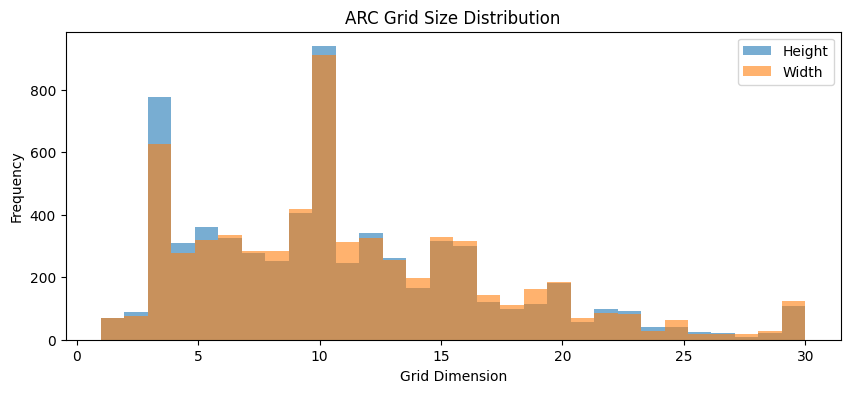

In [8]:
#cell 9
heights = [s[0] for s in stats["grid_shapes"]]
widths = [s[1] for s in stats["grid_shapes"]]

plt.figure(figsize=(10, 4))

plt.hist(
    heights,
    bins=30,
    alpha=0.6,
    label="Height"
)

plt.hist(
    widths,
    bins=30,
    alpha=0.6,
    label="Width"
)

plt.xlabel("Grid Dimension")
plt.ylabel("Frequency")
plt.title("ARC Grid Size Distribution")

plt.legend()
plt.show()

In [9]:
#cell 10
from sklearn.model_selection import train_test_split

task_ids = sorted([
    f.replace(".json", "")
    for f in train_files
])

train_ids, val_ids = train_test_split(
    task_ids,
    test_size=0.20,
    random_state=42
)

print("Training tasks:", len(train_ids))
print("Validation tasks:", len(val_ids))

# Save split
split_path = os.path.join(
    PROJECT_DIR,
    "experiments",
    "task_split.json"
)

with open(split_path, "w") as f:

    json.dump(
        {
            "train_ids": sorted(train_ids),
            "val_ids": sorted(val_ids),
            "random_seed": 42
        },
        f,
        indent=2
    )

print("Task split saved:", split_path)

Training tasks: 800
Validation tasks: 200
Task split saved: /kaggle/working/GridMind/experiments/task_split.json


In [10]:
#cell 11
import os
import json
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

GRID_SIZE = 30
NUM_CHANNELS = 11
NUM_COLORS = 10

def encode_grid(grid):
    grid = np.array(grid, dtype=np.int64)

    h, w = grid.shape

    encoded = np.zeros(
        (NUM_CHANNELS, GRID_SIZE, GRID_SIZE),
        dtype=np.float32
    )

    # One-hot colour encoding
    for color in range(NUM_COLORS):
        encoded[color, :h, :w] = (grid == color)

    # Valid-cell mask
    encoded[10, :h, :w] = 1.0

    return torch.tensor(encoded), h, w


def encode_target(grid):
    grid = np.array(grid, dtype=np.int64)

    h, w = grid.shape

    target = torch.full(
        (GRID_SIZE, GRID_SIZE),
        -100,
        dtype=torch.long
    )

    target[:h, :w] = torch.tensor(grid)

    return target, h, w

In [11]:
#cell 12
class GridMindDataset(Dataset):

    def __init__(self, task_ids, data_dir, seed=42):
        self.task_ids = list(task_ids)
        self.data_dir = data_dir
        self.seed = seed
        self.epoch = 0

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __len__(self):
        return len(self.task_ids)

    def __getitem__(self, idx):

        task_id = self.task_ids[idx]
        file_path = os.path.join(
            self.data_dir,
            task_id + ".json"
        )

        with open(file_path, "r") as f:
            task = json.load(f)

        examples = task["train"]

        # Deterministic but different query across epochs
        rng = random.Random(
            self.seed + self.epoch * 100003 + idx
        )

        query_idx = rng.randrange(len(examples))

        query_example = examples[query_idx]

        support_examples = [
            example
            for i, example in enumerate(examples)
            if i != query_idx
        ]

        support_inputs = []
        support_outputs = []

        for example in support_examples:

            x, _, _ = encode_grid(example["input"])
            y, _, _ = encode_grid(example["output"])

            support_inputs.append(x)
            support_outputs.append(y)

        query_input, qh, qw = encode_grid(
            query_example["input"]
        )

        query_target, th, tw = encode_target(
            query_example["output"]
        )

        return {
            "support_inputs": torch.stack(support_inputs),
            "support_outputs": torch.stack(support_outputs),
            "query_input": query_input,
            "query_target": query_target,
            "query_size": torch.tensor([qh, qw]),
            "target_size": torch.tensor([th, tw]),
            "task_id": task_id
        }

In [12]:
#cell 13
def gridmind_collate(batch):

    batch_size = len(batch)
    max_support = max(
        item["support_inputs"].shape[0]
        for item in batch
    )

    support_inputs = torch.zeros(
        batch_size, max_support,
        NUM_CHANNELS, GRID_SIZE, GRID_SIZE
    )

    support_outputs = torch.zeros_like(support_inputs)

    support_mask = torch.zeros(
        batch_size, max_support,
        dtype=torch.bool
    )

    for i, item in enumerate(batch):

        n = item["support_inputs"].shape[0]

        support_inputs[i, :n] = item["support_inputs"]
        support_outputs[i, :n] = item["support_outputs"]

        support_mask[i, :n] = True

    return {
        "support_inputs": support_inputs,
        "support_outputs": support_outputs,
        "support_mask": support_mask,

        "query_input": torch.stack([
            item["query_input"] for item in batch
        ]),

        "query_target": torch.stack([
            item["query_target"] for item in batch
        ]),

        "query_size": torch.stack([
            item["query_size"] for item in batch
        ]),

        "target_size": torch.stack([
            item["target_size"] for item in batch
        ]),

        "task_id": [
            item["task_id"] for item in batch
        ]
    }

In [13]:
#cell 14
train_dataset = GridMindDataset(
    train_ids,
    TRAIN_DIR,
    seed=42
)

val_dataset = GridMindDataset(
    val_ids,
    TRAIN_DIR,
    seed=1000
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=gridmind_collate,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=gridmind_collate,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 100
Validation batches: 25


In [14]:
#cell 15
batch = next(iter(train_loader))

for key, value in batch.items():

    if torch.is_tensor(value):
        print(key, value.shape, value.dtype)

    elif isinstance(value, list):
        print(key, value[:3])

support_inputs torch.Size([8, 2, 11, 30, 30]) torch.float32
support_outputs torch.Size([8, 2, 11, 30, 30]) torch.float32
support_mask torch.Size([8, 2]) torch.bool
query_input torch.Size([8, 11, 30, 30]) torch.float32
query_target torch.Size([8, 30, 30]) torch.int64
query_size torch.Size([8, 2]) torch.int64
target_size torch.Size([8, 2]) torch.int64
task_id ['e26a3af2', '7e576d6e', 'bf32578f']


In [15]:
#cell 16
import torch
import torch.nn as nn
import torch.nn.functional as F

class GridMindConfig:
    grid_size = 30
    input_channels = 11
    num_colors = 10

    hidden_dim = 128
    num_heads = 4
    num_transformer_layers = 3
    dropout = 0.1

In [16]:
#cell 17
class GridEncoder(nn.Module):

    def __init__(self, config):
        super().__init__()

        self.encoder = nn.Sequential(

            nn.Conv2d(
                config.input_channels,
                64,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.GELU(),

            nn.Conv2d(
                64,
                96,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(96),
            nn.GELU(),

            nn.Conv2d(
                96,
                config.hidden_dim,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(config.hidden_dim),
            nn.GELU()
        )

    def forward(self, x):
        return self.encoder(x)

In [17]:
#cell 18
class GridMind(nn.Module):

    def __init__(self, config):
        super().__init__()

        self.config = config
        d = config.hidden_dim
        g = config.grid_size

        self.encoder = GridEncoder(config)

        # Learnable positional embeddings
        self.position_embedding = nn.Parameter(
            torch.randn(1, 225, d) * 0.02
        )

        # Role 0 = input grid, Role 1 = output grid
        self.role_embedding = nn.Parameter(
            torch.randn(1, 2, 1, d) * 0.02
        )

        # Query attends to support memory
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d,
            nhead=config.num_heads,
            dim_feedforward=4 * d,
            dropout=config.dropout,
            batch_first=True,
            norm_first=True
        )

        self.reasoner = nn.TransformerDecoder(
            decoder_layer,
            num_layers=config.num_transformer_layers
        )

        self.norm = nn.LayerNorm(d)

        # Spatial reconstruction
        self.grid_decoder = nn.Sequential(
            nn.Conv2d(d + config.input_channels, 128, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(128, 64, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(64, config.num_colors, 1)
        )

        # Output height and width prediction
        self.size_head = nn.Sequential(
            nn.Linear(2 * d, d),
            nn.GELU(),
            nn.Dropout(config.dropout),
            nn.Linear(d, 2 * g)
        )

    def encode_tokens(self, x):

        features = self.encoder(x)

        b, d, h, w = features.shape

        tokens = features.flatten(2).transpose(1, 2)

        tokens = tokens + self.position_embedding

        return tokens

    def make_spatial_mask(self, x):

        # Valid-cell mask from channel 10
        mask = x[:, 10:11]

        mask = F.max_pool2d(
            mask,
            kernel_size=2,
            stride=2
        )

        return mask.flatten(1) > 0

    def forward(
        self,
        support_inputs,
        support_outputs,
        query_input,
        support_mask
    ):

        B, S, C, H, W = support_inputs.shape

        # Encode support inputs and outputs
        sx = support_inputs.reshape(
            B * S, C, H, W
        )

        sy = support_outputs.reshape(
            B * S, C, H, W
        )

        support_input_tokens = self.encode_tokens(sx)
        support_output_tokens = self.encode_tokens(sy)

        # Restore batch and support dimensions
        support_input_tokens = support_input_tokens.reshape(
            B, S, 225, -1
        )

        support_output_tokens = support_output_tokens.reshape(
            B, S, 225, -1
        )

        # Add role information
        support_input_tokens = (
            support_input_tokens + self.role_embedding[:, 0]
        )

        support_output_tokens = (
            support_output_tokens + self.role_embedding[:, 1]
        )

        # Combine support input-output tokens
        support_memory = torch.cat(
            [support_input_tokens, support_output_tokens],
            dim=2
        )

        # Flatten all support examples into one memory
        support_memory = support_memory.reshape(
            B, S * 450, -1
        )

        # Query encoding
        query_tokens = self.encode_tokens(query_input)

        # Build attention masks
        input_mask = self.make_spatial_mask(sx).reshape(
            B, S, 225
        )

        output_mask = self.make_spatial_mask(sy).reshape(
            B, S, 225
        )

        memory_mask = torch.cat(
            [input_mask, output_mask],
            dim=2
        )

        # Mark padded support examples as invalid
        memory_mask = (
            memory_mask &
            support_mask.unsqueeze(-1)
        )

        memory_mask = memory_mask.reshape(
            B, S * 450
        )

        query_mask = self.make_spatial_mask(query_input)

        # Cross-attention reasoning
        reasoning = self.reasoner(
            tgt=query_tokens,
            memory=support_memory,
            tgt_key_padding_mask=~query_mask,
            memory_key_padding_mask=~memory_mask
        )

        reasoning = self.norm(reasoning)

        # Reconstruct spatial feature map
        spatial = reasoning.transpose(1, 2).reshape(
            B,
            self.config.hidden_dim,
            15,
            15
        )

        spatial = F.interpolate(
            spatial,
            size=(30, 30),
            mode="bilinear",
            align_corners=False
        )

        # Combine original query grid with reasoning features
        decoder_input = torch.cat(
            [spatial, query_input],
            dim=1
        )

        colour_logits = self.grid_decoder(decoder_input)

        # Predict output dimensions
        valid_query = query_mask.unsqueeze(-1).float()

        query_pooled = (
            query_tokens * valid_query
        ).sum(dim=1) / valid_query.sum(dim=1).clamp(min=1)

        reasoning_pooled = (
            reasoning * valid_query
        ).sum(dim=1) / valid_query.sum(dim=1).clamp(min=1)

        pooled = torch.cat(
            [query_pooled, reasoning_pooled],
            dim=-1
        )

        size_logits = self.size_head(pooled)

        height_logits = size_logits[:, :30]
        width_logits = size_logits[:, 30:]

        return {
            "colour_logits": colour_logits,
            "height_logits": height_logits,
            "width_logits": width_logits
        }

In [18]:
#cell 19
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

config = GridMindConfig()

model = GridMind(config).to(device)

print("Device:", device)
print("Total parameters:", sum(
    p.numel() for p in model.parameters()
))

Device: cuda
Total parameters: 1271462


In [19]:
#cell 20
batch = next(iter(train_loader))

test_batch = {
    key: value[:2] if torch.is_tensor(value) else value[:2]
    for key, value in batch.items()
}

support_inputs = test_batch["support_inputs"].to(device)
support_outputs = test_batch["support_outputs"].to(device)
query_input = test_batch["query_input"].to(device)
support_mask = test_batch["support_mask"].to(device)

model.eval()

with torch.no_grad():

    predictions = model(
        support_inputs,
        support_outputs,
        query_input,
        support_mask
    )

for key, value in predictions.items():
    print(key, value.shape)

colour_logits torch.Size([2, 10, 30, 30])
height_logits torch.Size([2, 30])
width_logits torch.Size([2, 30])


In [20]:
#cell 21
import torch
import torch.nn as nn
import torch.nn.functional as F

def calculate_loss(predictions, batch):

    target = batch["query_target"].to(device)
    target_size = batch["target_size"].to(device)

    colour_logits = predictions["colour_logits"]
    height_logits = predictions["height_logits"]
    width_logits = predictions["width_logits"]

    # Ignore padded cells (-100)
    colour_loss = F.cross_entropy(
        colour_logits,
        target,
        ignore_index=-100
    )

    # Convert actual dimensions into zero-based classes
    height_loss = F.cross_entropy(
        height_logits,
        target_size[:, 0] - 1
    )

    width_loss = F.cross_entropy(
        width_logits,
        target_size[:, 1] - 1
    )

    total_loss = (
        colour_loss
        + 0.5 * height_loss
        + 0.5 * width_loss
    )

    return {
        "total": total_loss,
        "colour": colour_loss,
        "height": height_loss,
        "width": width_loss
    }

In [21]:
#cell 22
import os

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR, "gridmind_best.pt"
)

In [22]:
#cell 23
@torch.no_grad()
def evaluate(model, loader):

    model.eval()

    total_loss = 0.0
    total_batches = 0

    correct_cells = 0
    total_cells = 0

    correct_sizes = 0
    exact_matches = 0
    total_tasks = 0

    for batch in loader:

        support_inputs = batch["support_inputs"].to(device)
        support_outputs = batch["support_outputs"].to(device)
        query_input = batch["query_input"].to(device)
        support_mask = batch["support_mask"].to(device)

        target = batch["query_target"].to(device)
        target_size = batch["target_size"].to(device)

        predictions = model(
            support_inputs,
            support_outputs,
            query_input,
            support_mask
        )

        losses = calculate_loss(predictions, batch)

        total_loss += losses["total"].item()
        total_batches += 1

        predicted_grid = predictions[
            "colour_logits"
        ].argmax(dim=1)

        predicted_height = (
            predictions["height_logits"].argmax(dim=1) + 1
        )

        predicted_width = (
            predictions["width_logits"].argmax(dim=1) + 1
        )

        for i in range(target.shape[0]):

            true_h, true_w = target_size[i].tolist()

            valid_target = target[i, :true_h, :true_w]
            valid_prediction = predicted_grid[i, :true_h, :true_w]

            correct_cells += (
                valid_prediction == valid_target
            ).sum().item()

            total_cells += true_h * true_w

            size_correct = (
                predicted_height[i].item() == true_h
                and predicted_width[i].item() == true_w
            )

            if size_correct:
                correct_sizes += 1

            grid_correct = torch.equal(
                valid_prediction,
                valid_target
            )

            if size_correct and grid_correct:
                exact_matches += 1

            total_tasks += 1

    return {
        "loss": total_loss / max(total_batches, 1),
        "cell_accuracy": correct_cells / max(total_cells, 1),
        "size_accuracy": correct_sizes / max(total_tasks, 1),
        "exact_match": exact_matches / max(total_tasks, 1)
    }

In [23]:
#cell 24
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

EPOCHS = 30
PATIENCE = 7

best_val_loss = float("inf")
epochs_without_improvement = 0

history = []

for epoch in range(EPOCHS):

    train_dataset.set_epoch(epoch)

    model.train()

    running_loss = 0.0
    batches = 0

    for batch in train_loader:

        support_inputs = batch["support_inputs"].to(device)
        support_outputs = batch["support_outputs"].to(device)
        query_input = batch["query_input"].to(device)
        support_mask = batch["support_mask"].to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(
            support_inputs,
            support_outputs,
            query_input,
            support_mask
        )

        losses = calculate_loss(predictions, batch)

        losses["total"].backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += losses["total"].item()
        batches += 1

    train_loss = running_loss / max(batches, 1)

    # Validation query remains fixed
    val_metrics = evaluate(model, val_loader)

    scheduler.step(val_metrics["loss"])

    current_lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        **val_metrics,
        "learning_rate": current_lr
    })

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Cell Acc: {val_metrics['cell_accuracy']:.4f} | "
        f"Size Acc: {val_metrics['size_accuracy']:.4f} | "
        f"Exact Match: {val_metrics['exact_match']:.4f}"
    )

    if val_metrics["loss"] < best_val_loss:

        best_val_loss = val_metrics["loss"]
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "config": {
                "hidden_dim": config.hidden_dim,
                "num_heads": config.num_heads,
                "num_transformer_layers": config.num_transformer_layers
            }
        }, BEST_MODEL_PATH)

        print("  Best checkpoint saved!")

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nTraining completed.")
print("Best validation loss:", best_val_loss)
print("Checkpoint:", BEST_MODEL_PATH)

Epoch 01/30 | Train Loss: 4.8132 | Val Loss: 4.4698 | Cell Acc: 0.6107 | Size Acc: 0.1150 | Exact Match: 0.0050
  Best checkpoint saved!
Epoch 02/30 | Train Loss: 4.2997 | Val Loss: 4.1289 | Cell Acc: 0.6424 | Size Acc: 0.1300 | Exact Match: 0.0050
  Best checkpoint saved!
Epoch 03/30 | Train Loss: 4.0365 | Val Loss: 3.9266 | Cell Acc: 0.6762 | Size Acc: 0.1400 | Exact Match: 0.0050
  Best checkpoint saved!
Epoch 04/30 | Train Loss: 3.8314 | Val Loss: 3.7526 | Cell Acc: 0.6799 | Size Acc: 0.1600 | Exact Match: 0.0050
  Best checkpoint saved!
Epoch 05/30 | Train Loss: 3.6630 | Val Loss: 3.5874 | Cell Acc: 0.6823 | Size Acc: 0.1800 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 06/30 | Train Loss: 3.4943 | Val Loss: 3.4785 | Cell Acc: 0.6806 | Size Acc: 0.1650 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 07/30 | Train Loss: 3.3417 | Val Loss: 3.3509 | Cell Acc: 0.6967 | Size Acc: 0.2200 | Exact Match: 0.0000
  Best checkpoint saved!
Epoch 08/30 | Train Loss: 3.2203 | Val Lo

In [24]:
#cell 25
train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=gridmind_collate,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=gridmind_collate,
    num_workers=0
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train batches: 400
Validation batches: 100


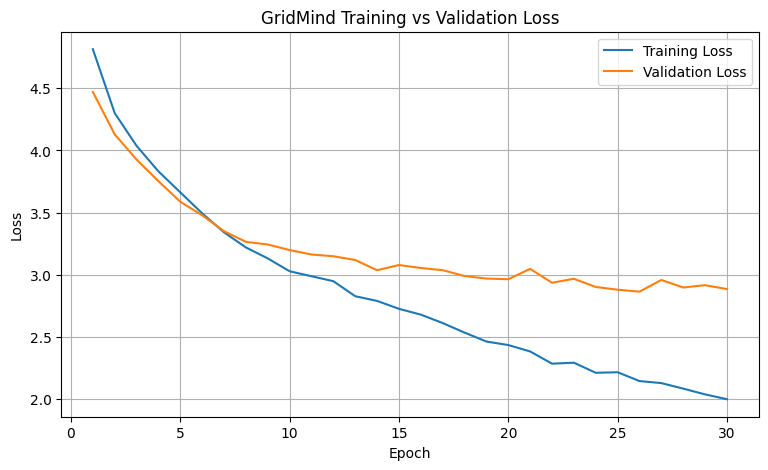

In [25]:
#cell 26
import matplotlib.pyplot as plt

epochs = [x["epoch"] for x in history]
train_losses = [x["train_loss"] for x in history]
val_losses = [x["loss"] for x in history]

plt.figure(figsize=(9, 5))

plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GridMind Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()